# 03: Boundary model: BiLSTM over frozen embeddings vs. the baseline

**Hypothesis:** a BiLSTM trained on thousands of real chapterings beats the unsupervised TextTiling baseline (02) at locating boundaries.

**Shipping rule** (0009 §7): the BiLSTM ships only if it beats the baseline on **validation F1@5s** in the **product setting** (~6 chapters/h). The oracle-count results are reported too, because the creators' references are much denser than "few and broad" (see 02).

Settings fixed by 02 (preliminary, 300 English videos):
- **Encoder: `e5-small`.** It ties MiniLM (F1@5s 10.8 vs 10.9); e5-small is chosen for its MIT licence.
- **Unit: `sentence`** (2–15 s). It has the highest ceiling: F1@5s 83.3 / F1@3s 72.8, against 70.8 / 47.2 for `block10`. The baseline differences between units were marginal.

Data: `01_data` → `interim/{train,val,es_val}.jsonl`. Section 2 below is also the **official baseline run on our validation split**. It uses the same units and encoder, so `02_baseline.ipynb` is not re-run on `val`; the preliminary 02 already settled units and encoder. Test sets (`test`, `es_test`) are **not touched** until `05_eval`.

In [1]:
import json, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from dotenv import load_dotenv
load_dotenv('../.env')
from lib import data as d, vidchapters as vc
from lib.units import UnitConfig
from lib.encode import Encoder
from lib.store import Store
from lib.build_store import build_store
from lib.baseline import boundary_scores
from lib.decoding import DecodeConfig
from lib.train import TrainConfig, train, evaluate_scores, evaluate_store, predict_scores
from lib.model import BoundaryTagger

ROOT = d.data_root()
ENCODER, UNIT = 'e5-small', UnitConfig(mode='sentence', min_s=2, max_s=15)
STORES = ROOT / 'embeddings' / f'{ENCODER}-sentence'
RUN = Path('runs/2026-09-28-boundaries'); RUN.mkdir(parents=True, exist_ok=True)
CKPT = ROOT / 'checkpoints' / 'boundaries'
PRODUCT = DecodeConfig(per_hour=6, min_len_s=60)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(DEVICE, STORES)

/home/pablo/projects/new_youtube_suite/backend/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


cuda /mnt/d/yts-experiments/m5-chapters/embeddings/e5-small-sentence


## 1. Encode train / val / es_val once (cached on the second drive)

In [2]:
enc = None
for split in ('train', 'val', 'es_val'):
    if (STORES / split / 'index.json').exists():
        print(split, 'cached'); continue
    enc = enc or Encoder(ENCODER, device=DEVICE)
    videos = list(vc.load_jsonl(ROOT / f'interim/{split}.jsonl'))
    t0 = time.time(); n = build_store(videos, enc, UNIT, STORES / split)
    print(f'{split}: {len(videos)} videos, {n} units, {time.time()-t0:.0f}s')
del enc; torch.cuda.empty_cache()
stores = {s: Store(STORES / s) for s in ('train', 'val', 'es_val')}
pd.DataFrame([dict(split=s, videos=len(st), units=int(sum(v['n'] for v in st.videos)),
                   positives_per_video=np.mean([len(v['labels']) for v in st.videos]),
                   units_per_positive=sum(v['n'] for v in st.videos) / max(1, sum(len(v['labels']) for v in st.videos)))
              for s, st in stores.items()]).set_index('split').round(1)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 6163.54it/s]

  64/9112 videos, 26149 units


  512/9112 videos, 218396 units


  960/9112 videos, 408180 units


...

  900/900 videos, 349835 units


val: 900 videos, 349835 units, 312s


  18/18 videos, 2694 units


es_val: 18 videos, 2694 units, 3s


,videos,units,positives_per_video,units_per_positive
split,,,,
train,9112,3591173,9.6,41.1
val,900,349835,9.8,39.5
es_val,18,2694,7.1,21.2


## 2. The bar to beat: the baseline over these same units

In [3]:
WINDOW = 10  # units ≈ 60 s with ~6 s sentences (best/near-best in 02)
base = lambda e, m: boundary_scores(e, window=WINDOW)
baseline = {}
for s in ('val', 'es_val'):
    for oracle in (False, True):
        baseline[s, oracle] = evaluate_scores(base, stores[s], PRODUCT, oracle)
pd.DataFrame(baseline).T.rename_axis(['split', 'oracle'])[['F1@5s', 'F1@3s', 'F1@30s', 'tIoU-F1', 'Pk', 'WindowDiff', 'count_MAE']]

F1@5s  F1@3s  F1@30s  tIoU-F1     Pk  WindowDiff  count_MAE
split  oracle                                                              
val    False    7.774  5.364  20.850   12.519  0.423       0.439      6.837
       True    11.531  7.947  34.230   20.979  0.420       0.447      0.711
es_val False   10.311  5.650  20.168   11.989  0.401       0.409      5.500
       True    15.735  9.149  38.073   23.369  0.349       0.372      0.556

## 3. BiLSTM training

A few configurations, 10 epochs each. The best epoch is kept by **validation F1@5s (product setting)**.

In [4]:
CONFIGS = {
    'default': TrainConfig(),
    'pos5': TrainConfig(pos_weight=5.0),
    'pos20': TrainConfig(pos_weight=20.0),
    'big': TrainConfig(proj=384, hidden=256),
}
runs = {}
for name, cfg in CONFIGS.items():
    print('=== ', name, cfg)
    t0 = time.time()
    runs[name] = train(stores['train'], stores['val'], cfg, CKPT / name, DEVICE, PRODUCT)
    print(f'{name}: {time.time()-t0:.0f}s, best epoch {runs[name]["best"]["epoch"]}, F1@5s {runs[name]["best"]["F1@5s"]}')

===  default TrainConfig(epochs=10, batch_size=16, lr=0.001, weight_decay=0.0001, pos_weight=10.0, neighbour_weight=0.3, max_units=2000, proj=256, hidden=128, layers=2, dropout=0.2, seed=0)


{"epoch": 1, "train_loss": 1.1917194744996857, "sec": 82.7, "F1@3s": 2.825, "F1@5s": 4.611, "P@5s": 8.311, "R@5s": 3.191, "F1@10s": 7.844, "F1@30s": 18.87, "tIoU-F1": 9.446, "mean_tIoU": 46.636, "Pk": 0.409, "WindowDiff": 0.433, "count_MAE": 6.837, "pred_chapters_mean": 5.08, "ref_chapters_mean": 11.252, "oracle_F1@5s": 7.358, "oracle_F1@3s": 4.745, "oracle_tIoU-F1": 13.703}


{"epoch": 2, "train_loss": 1.056326377182676, "sec": 53.7, "F1@3s": 5.91, "F1@5s": 8.354, "P@5s": 15.464, "R@5s": 5.723, "F1@10s": 12.66, "F1@30s": 21.437, "tIoU-F1": 13.021, "mean_tIoU": 50.563, "Pk": 0.406, "WindowDiff": 0.426, "count_MAE": 6.837, "pred_chapters_mean": 5.08, "ref_chapters_mean": 11.252, "oracle_F1@5s": 12.358, "oracle_F1@3s": 8.872, "oracle_tIoU-F1": 21.647}


{"epoch": 3, "train_loss": 0.9563699277869442, "sec": 53.7, "F1@3s": 10.588, "F1@5s": 13.991, "P@5s": 24.229, "R@5s": 9.836, "F1@10s": 19.341, "F1@30s": 27.584, "tIoU-F1": 15.966, "mean_tIoU": 53.368, "Pk": 0.386, "WindowDiff": 0.406, "count_MAE": 6.838, "pred_chapters_mean": 5.079, "ref_chapters_mean": 11.252, "oracle_F1@5s": 19.171, "oracle_F1@3s": 14.327, "oracle_tIoU-F1": 26.589}


{"epoch": 4, "train_loss": 0.9057624537693827, "sec": 53.2, "F1@3s": 11.389, "F1@5s": 14.566, "P@5s": 25.451, "R@5s": 10.202, "F1@10s": 19.623, "F1@30s": 27.241, "tIoU-F1": 15.913, "mean_tIoU": 53.374, "Pk": 0.386, "WindowDiff": 0.405, "count_MAE": 6.838, "pred_chapters_mean": 5.079, "ref_chapters_mean": 11.252, "oracle_F1@5s": 19.774, "oracle_F1@3s": 14.812, "oracle_tIoU-F1": 27.133}


...

{"epoch": 6, "train_loss": 0.8269108830836781, "sec": 99.3, "F1@3s": 12.722, "F1@5s": 16.352, "P@5s": 27.735, "R@5s": 11.594, "F1@10s": 21.829, "F1@30s": 31.161, "tIoU-F1": 17.97, "mean_tIoU": 55.071, "Pk": 0.368, "WindowDiff": 0.387, "count_MAE": 6.837, "pred_chapters_mean": 5.08, "ref_chapters_mean": 11.252, "oracle_F1@5s": 21.487, "oracle_F1@3s": 16.481, "oracle_tIoU-F1": 30.032}


{"epoch": 7, "train_loss": 0.8150060337363628, "sec": 99.2, "F1@3s": 12.703, "F1@5s": 16.376, "P@5s": 27.782, "R@5s": 11.61, "F1@10s": 22.143, "F1@30s": 30.85, "tIoU-F1": 18.116, "mean_tIoU": 55.005, "Pk": 0.366, "WindowDiff": 0.386, "count_MAE": 6.837, "pred_chapters_mean": 5.08, "ref_chapters_mean": 11.252, "oracle_F1@5s": 21.485, "oracle_F1@3s": 16.47, "oracle_tIoU-F1": 29.915}


{"epoch": 8, "train_loss": 0.8046065374947431, "sec": 99.0, "F1@3s": 13.197, "F1@5s": 16.864, "P@5s": 28.554, "R@5s": 11.966, "F1@10s": 22.949, "F1@30s": 31.628, "tIoU-F1": 18.625, "mean_tIoU": 55.526, "Pk": 0.361, "WindowDiff": 0.381, "count_MAE": 6.837, "pred_chapters_mean": 5.08, "ref_chapters_mean": 11.252, "oracle_F1@5s": 21.997, "oracle_F1@3s": 16.823, "oracle_tIoU-F1": 30.419}


{"epoch": 9, "train_loss": 0.7959886203993831, "sec": 99.2, "F1@3s": 13.191, "F1@5s": 16.85, "P@5s": 28.615, "R@5s": 11.94, "F1@10s": 22.585, "F1@30s": 31.268, "tIoU-F1": 18.154, "mean_tIoU": 55.241, "Pk": 0.363, "WindowDiff": 0.383, "count_MAE": 6.837, "pred_chapters_mean": 5.08, "ref_chapters_mean": 11.252, "oracle_F1@5s": 21.984, "oracle_F1@3s": 16.855, "oracle_tIoU-F1": 30.201}


{"epoch": 10, "train_loss": 0.7901779136636801, "sec": 99.3, "F1@3s": 13.188, "F1@5s": 16.852, "P@5s": 28.396, "R@5s": 11.982, "F1@10s": 22.885, "F1@30s": 31.683, "tIoU-F1": 18.531, "mean_tIoU": 55.572, "Pk": 0.362, "WindowDiff": 0.382, "count_MAE": 6.837, "pred_chapters_mean": 5.08, "ref_chapters_mean": 11.252, "oracle_F1@5s": 22.061, "oracle_F1@3s": 16.838, "oracle_tIoU-F1": 30.852}
big: 994s, best epoch 8, F1@5s 16.864


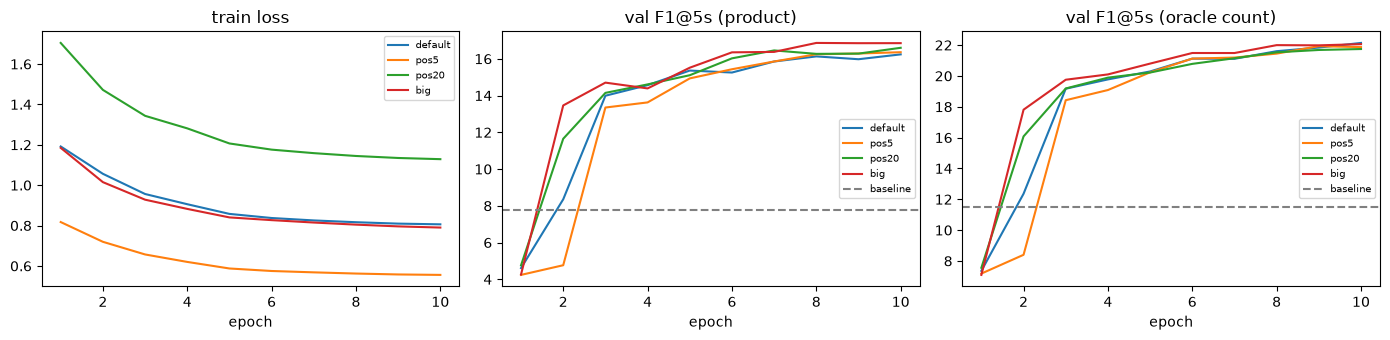

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
for name, r in runs.items():
    h = pd.DataFrame(r['history'])
    ax[0].plot(h.epoch, h.train_loss, label=name); ax[1].plot(h.epoch, h['F1@5s'], label=name); ax[2].plot(h.epoch, h['oracle_F1@5s'], label=name)
for a, t, key in zip(ax, ('train loss', 'val F1@5s (product)', 'val F1@5s (oracle count)'), (None, (False,), (True,))):
    a.set_title(t); a.set_xlabel('epoch')
    if key: a.axhline(baseline['val', key[0]]['F1@5s'], color='grey', ls='--', label='baseline')
    a.legend(fontsize=7)
plt.tight_layout(); plt.savefig(RUN / 'learning_curves.png', dpi=110); plt.show()

## 4. Best model vs. baseline: English validation and **Spanish** (cross-lingual transfer)

In [6]:
best_name = max(runs, key=lambda n: runs[n]['best']['F1@5s'])
ck = torch.load(CKPT / best_name / 'best.pt')
model = BoundaryTagger(**ck['model_config']); model.load_state_dict(ck['state_dict']); model.to(DEVICE)
rows = []
for s in ('val', 'es_val'):
    for oracle in (False, True):
        rows.append(dict(split=s, oracle=oracle, method='baseline', **baseline[s, oracle]))
        rows.append(dict(split=s, oracle=oracle, method=f'bilstm:{best_name}', **evaluate_store(model, stores[s], DEVICE, PRODUCT, oracle)))
cmp = pd.DataFrame(rows)
cmp[['split', 'oracle', 'method', 'F1@5s', 'F1@3s', 'F1@30s', 'tIoU-F1', 'mean_tIoU', 'Pk', 'WindowDiff', 'count_MAE']]

,split,oracle,method,F1@5s,F1@3s,F1@30s,tIoU-F1,mean_tIoU,Pk,WindowDiff,count_MAE
0,val,False,baseline,7.774,5.364,20.850,12.519,50.109,0.423,0.439,6.837
1,val,False,bilstm:big,16.864,13.197,31.628,18.625,55.526,0.361,0.381,6.837
2,val,True,baseline,11.531,7.947,34.230,20.979,56.327,0.420,0.447,0.711
3,val,True,bilstm:big,21.997,16.823,44.847,30.419,62.801,0.335,0.367,0.697
4,es_val,False,baseline,10.311,5.650,20.168,11.989,50.326,0.401,0.409,5.500
5,es_val,False,bilstm:big,8.167,5.256,22.333,12.389,52.269,0.347,0.361,5.500
6,es_val,True,baseline,15.735,9.149,38.073,23.369,59.100,0.349,0.372,0.556
7,es_val,True,bilstm:big,10.982,5.657,39.102,25.755,61.549,0.334,0.371,0.556


In [7]:
val_p = cmp[(cmp.split == 'val') & ~cmp.oracle].set_index('method')['F1@5s']
ships = val_p[f'bilstm:{best_name}'] > val_p['baseline']
print(f'Shipping rule, val F1@5s (product): BiLSTM {val_p[f"bilstm:{best_name}"]:.2f} vs baseline {val_p["baseline"]:.2f} -> '
      + ('BiLSTM ships' if ships else 'BASELINE ships'))

Shipping rule, val F1@5s (product): BiLSTM 16.86 vs baseline 7.77 -> BiLSTM ships


## 5. Examples: scores from both methods on one English and one Spanish video

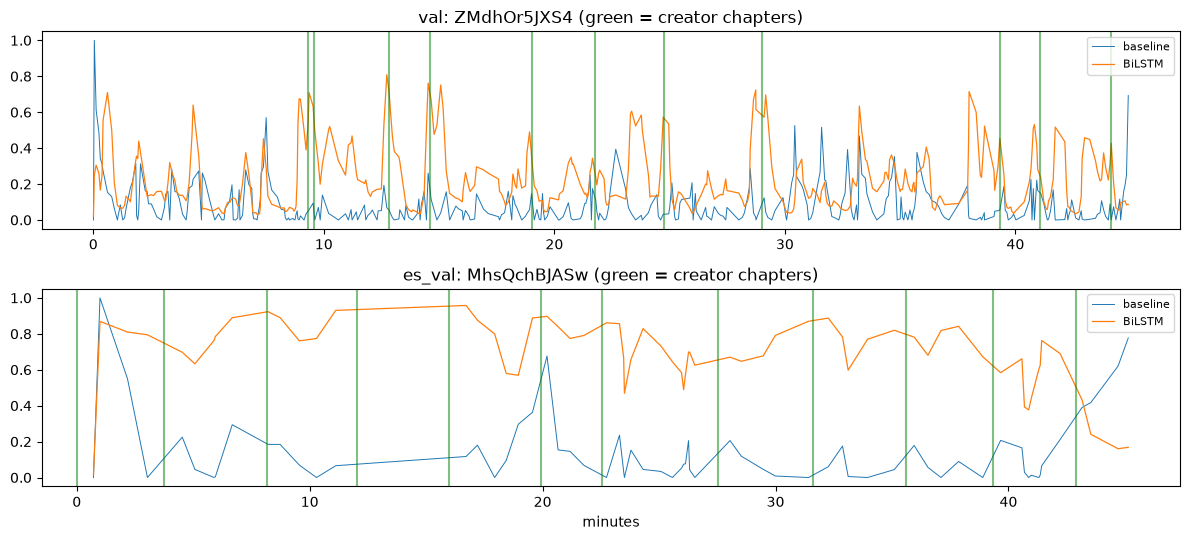

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5.5))
for ax, s in zip(axes, ('val', 'es_val')):
    st = stores[s]; i = int(np.argmin([abs(v['duration'] - 45 * 60) for v in st.videos]))
    e, m = st.get(i); t = np.array(m['unit_starts']) / 60
    ax.plot(t, boundary_scores(e, window=WINDOW), lw=.7, label='baseline')
    ax.plot(t, predict_scores(model, e, m['unit_starts'], m['duration'], DEVICE), lw=.9, label='BiLSTM')
    for c in m['chapter_starts']: ax.axvline(c / 60, color='green', alpha=.5)
    ax.set_title(f'{s}: {m["vid"]} (green = creator chapters)'); ax.legend(fontsize=8)
axes[-1].set_xlabel('minutes'); plt.tight_layout(); plt.savefig(RUN / 'examples.png', dpi=110); plt.show()

In [9]:
json.dump(dict(encoder=ENCODER, unit=UNIT.__dict__, decode_product=PRODUCT.__dict__, baseline_window_units=WINDOW,
               configs={k: v.__dict__ for k, v in CONFIGS.items()}), open(RUN / 'config.json', 'w'), indent=1)
json.dump(dict(best=best_name, best_epoch=runs[best_name]['best']['epoch'], bilstm_ships=bool(ships),
               comparison=json.loads(cmp.to_json(orient='records')),
               histories={k: r['history'] for k, r in runs.items()}), open(RUN / 'metrics.json', 'w'), indent=1)
print('saved to', RUN)

saved to runs/2026-09-28-boundaries
